# 06. 이항트리모형을 이용한 옵션 가치평가

1기간의 손계산을 NumPy 배열로 옮긴 뒤, CRR 트리·미국형 옵션·CSV 일괄평가로 확장합니다. 마지막 CEV와 Heston 트리는 선택 학습입니다.

**사용 방법**

- 위에서부터 셀을 순서대로 실행하세요. 이 노트북만 열어도 필요한 함수가 모두 정의됩니다.
- 각 실행 셀 아래에는 실제 실행 결과가 저장되어 있습니다. 함수 정의와 변수 설정 셀은 출력이 없어도 정상입니다.
- `강의록의 출력 예시`는 본문의 비교용 텍스트입니다. 바로 앞 코드 셀의 실제 출력과 구분합니다.
- `data` 폴더를 노트북 옆에 두세요. CSV 평가 결과는 `output` 폴더에 저장합니다.
- 금리·변동성은 소수로, 만기는 연 단위로 입력합니다. 위험중립측도는 $\mathbb{Q}$로 표기합니다.

**학습 흐름:** 1기간 가격과 복제 → CRR 계수 → backward induction → 미국형 조기행사 → 수렴과 CSV → CEV·Heston.

In [1]:
%matplotlib inline

## 실습 준비

필요한 패키지와 기본 입력을 준비합니다. 가격·금리·변동성에는 실수를, 단계 수에는 정수를 사용합니다.

### 이번 장에서 사용할 라이브러리 불러오기

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binom

### 기본 실수 입력

In [3]:
spot = 100.0
strike = 100.0
rate = 0.05
volatility = 0.20

## 1기간 이항트리모형

먼저 만기주가와 payoff를 구합니다. 무차익 조건 $d<e^{(r-q)\Delta t}<u$를 확인한 다음 $p_{\mathbb{Q}}=(e^{(r-q)\Delta t}-d)/(u-d)$로 가격을 계산합니다. 복제비용과 put–call parity로 결과를 확인하세요.

### 1기간의 기초자산 가격과 옵션 payoff

In [4]:
spot = 100.0
strike = 100.0
up = 1.20
down = 0.80

stock_up = spot * up
stock_down = spot * down

call_up = max(stock_up - strike, 0.0)
call_down = max(stock_down - strike, 0.0)
put_up = max(strike - stock_up, 0.0)
put_down = max(strike - stock_down, 0.0)

print("stock up:", stock_up)
print("stock down:", stock_down)
print("call payoff:", call_up, call_down)
print("put payoff:", put_up, put_down)

stock up: 120.0
stock down: 80.0
call payoff: 20.0 0.0
put payoff: 0.0 20.0


**강의록 Listing 4**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
stock up: 120.0
stock down: 80.0
call payoff: 20.0 0.0
put payoff: 0.0 20.0
```

### 1기간 무차익 조건 확인하기

In [5]:
rate = 0.05
dividend_yield = 0.0
delta_t = 1.0

growth = np.exp((rate - dividend_yield) * delta_t)

print("down:", down)
print("risk-neutral growth:", growth)
print("up:", up)

if not (down < growth < up):
    raise ValueError("No-arbitrage condition failed")

down: 0.8
risk-neutral growth: 1.0512710963760241
up: 1.2


**강의록 Listing 6**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
down: 0.8
risk-neutral growth: 1.0512710963760241
up: 1.2
```

### 위험중립확률로 1기간 콜옵션과 풋옵션 평가하기

In [6]:
probability_up = (growth - down) / (up - down)
discount = np.exp(-rate * delta_t)

call_price = discount * (probability_up * call_up + (1.0 - probability_up) * call_down)
put_price = discount * (probability_up * put_up + (1.0 - probability_up) * put_down)

print(f"risk-neutral probability: {probability_up:.10f}")
print(f"call price: {call_price:.10f}")
print(f"put price: {put_price:.10f}")

risk-neutral probability: 0.6281777409
call price: 11.9508230200
put price: 7.0737654700


**강의록 Listing 8**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
risk-neutral probability: 0.6281777409
call price: 11.9508230200
put price: 7.0737654700
```

### 콜옵션의 복제비용과 위험중립가격 비교

In [7]:
delta = (call_up - call_down) / (stock_up - stock_down)
bond_today = discount * (stock_up * call_down - stock_down * call_up) / (stock_up - stock_down)
replicating_cost = delta * spot + bond_today

print(f"delta: {delta:.10f}")
print(f"bond today: {bond_today:.10f}")
print(f"replicating cost: {replicating_cost:.10f}")
print(np.isclose(replicating_cost, call_price))

delta: 0.5000000000
bond today: -38.0491769800
replicating cost: 11.9508230200
True


**강의록 Listing 10**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
delta: 0.5000000000
bond today: -38.0491769800
replicating cost: 11.9508230200
True
```

### 1기간 put–call parity 검산

In [8]:
left_side = call_price - put_price
right_side = (
    spot * np.exp(-dividend_yield * delta_t) - strike * np.exp(-rate * delta_t)
)

print(f"left side: {left_side:.10f}")
print(f"right side: {right_side:.10f}")
print(np.isclose(left_side, right_side, rtol=1.0e-12, atol=1.0e-12))

left side: 4.8770575499
right side: 4.8770575499
True


**강의록 Listing 12**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
left side: 4.8770575499
right side: 4.8770575499
True
```

## CRR 방식으로 상승·하락배수 정하기

$\Delta t=T/m$, $u=e^{\sigma\sqrt{\Delta t}}$, $d=1/u$를 사용합니다. 아래 함수는 잘못된 입력과 무차익 조건 위반을 오류로 알려 줍니다.

### CRR 계수를 계산하는 함수

정수 단계 수와 유효한 모형 입력을 확인하는 부분을 함께 읽어 보세요.

In [9]:
def crr_parameters(
    maturity: float,
    rate: float,
    volatility: float,
    steps: int,
    dividend_yield: float = 0.0,
) -> tuple[float, float, float, float]:
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if maturity <= 0.0:
        raise ValueError("maturity must be positive")
    if volatility <= 0.0:
        raise ValueError("volatility must be positive")
    if steps <= 0:
        raise ValueError("steps must be positive")

    delta_t = maturity / steps
    up = np.exp(volatility * np.sqrt(delta_t))
    down = 1.0 / up
    growth = np.exp((rate - dividend_yield) * delta_t)

    if not (down < growth < up):
        raise ValueError("No-arbitrage condition failed")

    probability_up = (growth - down) / (up - down)
    return float(delta_t), float(up), float(down), float(probability_up)

### 2기간 CRR 계수 확인

In [10]:
delta_t, up, down, probability_up = crr_parameters(
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    steps=2,
    dividend_yield=0.0,
)

print(f"delta_t: {delta_t:.10f}")
print(f"up: {up:.10f}")
print(f"down: {down:.10f}")
print(f"risk-neutral probability: {probability_up:.10f}")

delta_t: 0.5000000000
up: 1.1519099102
down: 0.8681234454
risk-neutral probability: 0.5539082889


**강의록 Listing 15**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
delta_t: 0.5000000000
up: 1.1519099102
down: 0.8681234454
risk-neutral probability: 0.5539082889
```

## 2기간 재결합트리

배열은 낮은 주가부터 높은 주가 순서입니다. 만기의 길이 3인 배열이 뒤로 한 단계 이동할 때마다 2, 1로 줄어드는 것을 확인하세요.

### 2기간 만기주가와 콜 payoff 배열

In [11]:
spot = 100.0
strike = 100.0
maturity = 1.0
rate = 0.05
dividend_yield = 0.0
volatility = 0.20
steps = 2

delta_t, up, down, probability_up = crr_parameters(
    maturity=maturity,
    rate=rate,
    volatility=volatility,
    steps=steps,
    dividend_yield=dividend_yield,
)

discount = np.exp(-rate * delta_t)
up_moves = np.arange(steps + 1, dtype=float)
down_moves = steps - up_moves

stock_at_maturity = spot * up**up_moves * down**down_moves
option_at_maturity = np.maximum(stock_at_maturity - strike, 0.0)

print(stock_at_maturity)
print(option_at_maturity)

[ 75.36383164 100.         132.68964411]
[ 0.          0.         32.68964411]


**강의록 Listing 17**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
[ 75.36383164 100.         132.68964411]
[ 0.          0.         32.68964411]
```

### 2기간 backward induction

In [12]:
option_at_time_1 = discount * (
    (1.0 - probability_up) * option_at_maturity[:-1]
    + probability_up * option_at_maturity[1:]
)
option_at_time_0 = discount * (
    (1.0 - probability_up) * option_at_time_1[:-1]
    + probability_up * option_at_time_1[1:]
)

print("time 1:", option_at_time_1)
print("time 0:", option_at_time_0)

time 1: [ 0.         17.65999981]
time 0: [9.54050134]


**강의록 Listing 19**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
time 1: [ 0.         17.65999981]
time 0: [9.54050134]
```

## 일반적인 m기간 옵션가격 함수

payoff를 계산하는 부분과 backward induction을 수행하는 부분을 함수로 나눕니다. `exercise_style`로 유럽형과 미국형을 선택할 수 있습니다.

### 콜옵션과 풋옵션의 payoff 함수

In [13]:
def option_payoff(stock_values, strike: float, option_type: str):
    stock_values = np.asarray(stock_values, dtype=float)
    strike = float(strike)
    option_type = option_type.lower()

    if option_type == "call":
        return np.maximum(stock_values - strike, 0.0)
    if option_type == "put":
        return np.maximum(strike - stock_values, 0.0)

    raise ValueError("option_type must be 'call' or 'put'")

### 일반적인 CRR 이항트리 가격함수

함수 정의 셀입니다. 바로 다음 셀에서 100기간 콜·풋을 계산합니다.

In [14]:
def binomial_option_price(
    spot: float,
    strike: float,
    maturity: float,
    rate: float,
    volatility: float,
    steps: int,
    option_type: str = "call",
    exercise_style: str = "european",
    dividend_yield: float = 0.0,
) -> float:
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    option_type = option_type.lower()
    exercise_style = exercise_style.lower()

    if spot <= 0.0:
        raise ValueError("spot must be positive")
    if strike <= 0.0:
        raise ValueError("strike must be positive")
    if maturity <= 0.0:
        raise ValueError("maturity must be positive")
    if volatility <= 0.0:
        raise ValueError("volatility must be positive")
    if steps <= 0:
        raise ValueError("steps must be a positive integer")
    if option_type not in {"call", "put"}:
        raise ValueError("option_type must be 'call' or 'put'")
    if exercise_style not in {"european", "american"}:
        raise ValueError("exercise_style must be 'european' or 'american'")

    delta_t = maturity / steps
    up = np.exp(volatility * np.sqrt(delta_t))
    down = 1.0 / up
    growth = np.exp((rate - dividend_yield) * delta_t)

    if not (down < growth < up):
        raise ValueError("No-arbitrage condition failed: down < growth < up")

    probability_up = (growth - down) / (up - down)
    discount = np.exp(-rate * delta_t)

    up_moves = np.arange(steps + 1, dtype=float)
    down_moves = steps - up_moves
    stock_values = spot * up**up_moves * down**down_moves
    option_values = option_payoff(stock_values, strike, option_type)

    for time_step in range(steps - 1, -1, -1):
        continuation_values = discount * (
            (1.0 - probability_up) * option_values[:-1]
            + probability_up * option_values[1:]
        )
        option_values = continuation_values

        if exercise_style == "american":
            up_moves = np.arange(time_step + 1, dtype=float)
            down_moves = time_step - up_moves
            stock_values = spot * up**up_moves * down**down_moves
            exercise_values = option_payoff(stock_values, strike, option_type)
            option_values = np.maximum(continuation_values, exercise_values)

    return float(option_values[0])

### 100기간 유럽형 옵션가격 계산

In [15]:
common_inputs = {
    "spot": 100.0,
    "strike": 100.0,
    "maturity": 1.0,
    "rate": 0.05,
    "volatility": 0.20,
    "steps": 100,
    "dividend_yield": 0.0,
}

call_price_100 = binomial_option_price(**common_inputs, option_type="call", exercise_style="european")
put_price_100 = binomial_option_price(**common_inputs, option_type="put", exercise_style="european")

print(f"call: {call_price_100:.10f}")
print(f"put: {put_price_100:.10f}")

call: 10.4306116622
put: 5.5535541123


**강의록 Listing 23**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
call: 10.4306116622
put: 5.5535541123
```

### 다기간 유럽형 가격의 parity 검산

In [16]:
spot = float(common_inputs["spot"])
strike = float(common_inputs["strike"])
maturity = float(common_inputs["maturity"])
rate = float(common_inputs["rate"])
dividend_yield = float(common_inputs["dividend_yield"])

parity_left = call_price_100 - put_price_100
parity_right = (
    spot * np.exp(-dividend_yield * maturity) - strike * np.exp(-rate * maturity)
)

assert np.isclose(
    parity_left,
    parity_right,
    rtol=1.0e-10,
    atol=1.0e-10,
)

print("Put-call parity passed.")

Put-call parity passed.


**강의록 Listing 25**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
Put-call parity passed.
```

## 유럽형 옵션의 직접 위험중립기대값

유럽형 옵션은 이항분포의 만기확률로도 계산할 수 있습니다. 같은 입력에서 두 구현의 결과가 일치하는지 확인합니다.

### 유럽형 옵션의 terminal expectation 계산

In [17]:
def european_binomial_price_terminal(
    spot: float,
    strike: float,
    maturity: float,
    rate: float,
    volatility: float,
    steps: int,
    option_type: str = "call",
    dividend_yield: float = 0.0,
) -> float:
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0:
        raise ValueError("spot and strike must be positive")
    delta_t, up, down, probability_up = crr_parameters(
        maturity=maturity,
        rate=rate,
        volatility=volatility,
        steps=steps,
        dividend_yield=dividend_yield,
    )

    up_moves_int = np.arange(steps + 1, dtype=int)
    up_moves = up_moves_int.astype(float)
    down_moves = steps - up_moves

    stock_values = spot * up**up_moves * down**down_moves
    payoffs = option_payoff(stock_values, strike, option_type)
    probabilities = binom.pmf(up_moves_int, steps, probability_up)

    price = np.exp(-rate * maturity) * np.sum(probabilities * payoffs)
    return float(price)

### 직접 기대값과 backward induction 비교

In [18]:
price_backward = binomial_option_price(**common_inputs, option_type="call")
price_terminal = european_binomial_price_terminal(**common_inputs, option_type="call")

print(f"backward: {price_backward:.12f}")
print(f"terminal: {price_terminal:.12f}")
print(
    np.isclose(
        price_backward,
        price_terminal,
        rtol=1.0e-11,
        atol=1.0e-11,
    )
)

backward: 10.430611662249
terminal: 10.430611662249
True


**강의록 Listing 28**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
backward: 10.430611662249
terminal: 10.430611662249
True
```

## 미국형 옵션과 조기행사

각 노드에서 보유를 계속하는 가치와 즉시 행사하는 가치 중 큰 값을 선택합니다. 미국형 풋의 가격이 유럽형 풋보다 작지 않은지, 무배당 콜의 두 가격은 일치하는지 확인합니다.

### 미국형 노드의 가치 선택

**강의록 Listing 29**

이미 정의한 가격함수 안의 한 줄을 다시 보여 주는 발췌입니다. 아래에서는 세 노드의 값을 준비하여 같은 연산을 실행합니다.

```python
option_values = np.maximum(continuation_values, exercise_values)
```

In [19]:
continuation_example = np.array([18.0, 6.0, 1.0], dtype=float)
exercise_example = np.array([20.0, 5.0, 0.0], dtype=float)
value_example = np.maximum(continuation_example, exercise_example)
pd.DataFrame({
    "continuation_value": continuation_example,
    "exercise_value": exercise_example,
    "american_value": value_example,
})

,continuation_value,exercise_value,american_value
0,18.0,20.0,20.0
1,6.0,5.0,6.0
2,1.0,0.0,1.0


### 100기간 풋옵션의 행사방식 비교

In [20]:
european_put = binomial_option_price(**common_inputs, option_type="put", exercise_style="european")
american_put = binomial_option_price(**common_inputs, option_type="put", exercise_style="american")

print(f"European put: {european_put:.10f}")
print(f"American put: {american_put:.10f}")
print(american_put >= european_put)

European put: 5.5535541123
American put: 6.0823544091
True


**강의록 Listing 31**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
European put: 5.5535541123
American put: 6.0823544091
True
```

### 미국형 풋의 노드별 행사결정 기록하기

가격뿐 아니라 각 노드의 보유가치·행사가치·행사 여부를 기록합니다.

In [21]:
def american_put_tree_details(
    spot: float,
    strike: float,
    maturity: float,
    rate: float,
    volatility: float,
    steps: int,
    dividend_yield: float = 0.0,
) -> list[dict]:
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    volatility = float(volatility)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [spot, strike, maturity, rate, volatility, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0:
        raise ValueError("spot and strike must be positive")
    delta_t, up, down, probability_up = crr_parameters(
        maturity=maturity,
        rate=rate,
        volatility=volatility,
        steps=steps,
        dividend_yield=dividend_yield,
    )
    discount = np.exp(-rate * delta_t)

    up_moves = np.arange(steps + 1, dtype=float)
    stock_values = spot * up**up_moves * down**(steps - up_moves)
    option_values = np.maximum(strike - stock_values, 0.0)
    records = []

    for time_step in range(steps - 1, -1, -1):
        continuation_values = discount * (
            (1.0 - probability_up) * option_values[:-1]
            + probability_up * option_values[1:]
        )

        up_moves = np.arange(time_step + 1, dtype=float)
        stock_values = spot * up**up_moves * down**(time_step - up_moves)
        exercise_values = np.maximum(strike - stock_values, 0.0)
        exercise_now = exercise_values > continuation_values

        for node in range(time_step + 1):
            records.append(
                {
                    "time_step": time_step,
                    "node": node,
                    "stock": stock_values[node],
                    "continuation": continuation_values[node],
                    "exercise": exercise_values[node],
                    "exercise_now": bool(exercise_now[node]),
                }
            )

        option_values = np.maximum(continuation_values, exercise_values)

    return records

### 실제로 조기행사하는 노드 확인

In [22]:
exercise_records = american_put_tree_details(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.05,
    volatility=0.20,
    steps=3,
)
exercise_table = pd.DataFrame(exercise_records)

print(exercise_table.loc[exercise_table["exercise_now"]])

   time_step  node      stock  continuation   exercise  exercise_now
0          2     0  79.378701     18.968445  20.621299          True


**강의록 Listing 34**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
   time_step  node      stock  continuation   exercise  exercise_now
0          2     0  79.378701     18.968445  20.621299          True
```

### 무배당 미국형 콜과 유럽형 콜 비교

In [23]:
european_call = binomial_option_price(**common_inputs, option_type="call", exercise_style="european")
american_call = binomial_option_price(**common_inputs, option_type="call", exercise_style="american")

print(f"European call: {european_call:.10f}")
print(f"American call: {american_call:.10f}")
print(
    np.isclose(
        european_call,
        american_call,
        rtol=1.0e-12,
        atol=1.0e-12,
    )
)

European call: 10.4306116622
American call: 10.4306116622
True


**강의록 Listing 36**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
European call: 10.4306116622
American call: 10.4306116622
True
```

## 단계 수에 따른 가격

단계 수를 늘리며 가격을 표와 로그축 그래프로 확인합니다. 이항트리 가격은 수렴하면서도 위아래로 진동할 수 있습니다.

### 단계 수별 유럽형 콜옵션 가격 계산

In [24]:
step_values = np.array([1, 2, 5, 10, 25, 50, 100, 250, 500, 1000], dtype=int)

prices = np.array(
    [
        binomial_option_price(
            spot=100.0,
            strike=100.0,
            maturity=1.0,
            rate=0.05,
            volatility=0.20,
            steps=int(steps),
            option_type="call",
            exercise_style="european",
        )
        for steps in step_values
    ],
    dtype=float,
)

convergence_table = pd.DataFrame({"steps": step_values, "call_price": prices})
print(convergence_table.to_string(index=False))

 steps  call_price
     1   12.162285
     2    9.540501
     5   10.805934
    10   10.253409
    25   10.520966
    50   10.410692
   100   10.430612
   250   10.442589
   500   10.446585
  1000   10.448584


**강의록 Listing 38**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
 steps  call_price
     1   12.162285
     2    9.540501
     5   10.805934
    10   10.253409
    25   10.520966
    50   10.410692
   100   10.430612
   250   10.442589
   500   10.446585
  1000   10.448584
```

### 단계 수와 이항트리 가격의 그래프

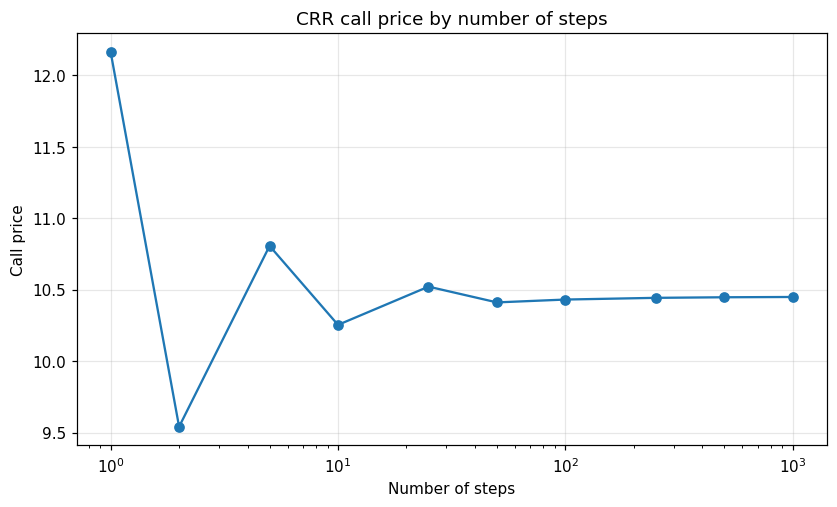

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), layout="constrained")
ax.plot(convergence_table["steps"], convergence_table["call_price"], marker="o")

ax.set_xscale("log")
ax.set_title("CRR call price by number of steps")
ax.set_xlabel("Number of steps")
ax.set_ylabel("Call price")
ax.grid(True, alpha=0.3)

plt.show()

## CSV의 각 계약에 가격함수 적용하기

**자료:** `data/european_option_market_data.csv`. 교육용 합성자료의 내재변동성을 입력하므로 이 비교는 구현과 수렴을 확인하는 실습입니다. 독립적인 시장가격 예측으로 해석하지 않습니다.

### 옵션 CSV 읽기

In [26]:
data_path = Path("data") / "european_option_market_data.csv"

dtype_map = {
    "contract_id": "string",
    "option_type": "string",
    "time_to_maturity": float,
    "spot_price": float,
    "strike_price": float,
    "risk_free_rate": float,
    "dividend_yield": float,
    "implied_volatility": float,
    "mid_price": float,
}

quotes = pd.read_csv(data_path, dtype=dtype_map)

### CSV의 각 계약에 CRR 가격 계산하기

In [27]:
model_prices = []

for row in quotes.itertuples(index=False):
    model_price = binomial_option_price(
        spot=row.spot_price,
        strike=row.strike_price,
        maturity=row.time_to_maturity,
        rate=row.risk_free_rate,
        volatility=row.implied_volatility,
        steps=300,
        option_type=row.option_type,
        exercise_style="european",
        dividend_yield=row.dividend_yield,
    )
    model_prices.append(model_price)

quotes["crr_price"] = np.asarray(model_prices, dtype=float)
quotes["pricing_error"] = quotes["crr_price"] - quotes["mid_price"]

display_columns = ["contract_id", "mid_price", "crr_price", "pricing_error"]
print(quotes[display_columns].head())

               contract_id  mid_price  crr_price  pricing_error
0  SYNTH100_20261208_C_080  20.498141  20.497469      -0.000672
1  SYNTH100_20261208_P_080   0.114254   0.113582      -0.000672
2  SYNTH100_20261208_C_090  11.297493  11.298643       0.001150
3  SYNTH100_20261208_P_090   0.826726   0.827876       0.001150
4  SYNTH100_20261208_C_095   7.404985   7.405845       0.000860


### 계산 결과를 CSV로 저장

In [28]:
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "option_quotes_with_crr_price.csv"
quotes.to_csv(output_path, index=False, encoding="utf-8-sig")

print(output_path)

output/option_quotes_with_crr_price.csv


## 직접 해보기

아래는 강의록 연습문제에서 요청하는 표의 열 이름입니다. 노트북 끝의 보충 실습에서는 미국형 풋의 조기행사 프리미엄을 직접 표로 만듭니다.

**강의록 Listing 43**

표의 열 이름을 나타낸 설명용 텍스트입니다. Python 실행 셀이 아닙니다.

```text
strike, european_put, american_put, early_exercise_premium
```

## 선택 학습: CEV와 Heston 트리

CEV에서는 주가에 따라 변동성이 달라집니다. Heston에서는 주가와 분산을 함께 추적합니다. 아래 교육용 트리는 재결합하지 않으므로 노드 수가 빠르게 증가합니다. 본문의 CEV 8단계와 Heston 6단계를 유지합니다.

### CEV 모형의 비재결합 이항트리 가격함수

CEV 확장: 이 함수의 노드 수는 단계마다 2배가 됩니다.

In [29]:
def cev_tree_price(
    spot,
    strike,
    maturity,
    rate,
    sigma0,
    beta,
    steps,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    sigma0 = float(sigma0)
    beta = float(beta)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [spot, strike, maturity, rate, sigma0, beta, dividend_yield]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0:
        raise ValueError("spot and strike must be positive")
    if maturity <= 0.0 or sigma0 <= 0.0 or not 0.0 < beta <= 1.0:
        raise ValueError("require T > 0, sigma0 > 0 and 0 < beta <= 1")
    if steps <= 0:
        raise ValueError("steps must be positive")

    dt = maturity / steps
    growth = np.exp((rate - dividend_yield) * dt)
    discount = np.exp(-rate * dt)

    stock_layers = [np.array([spot], dtype=float)]
    probability_layers = []

    for _ in range(steps):
        current_stock = stock_layers[-1]
        local_vol = sigma0 * (current_stock / spot) ** (beta - 1.0)
        up = np.exp(local_vol * np.sqrt(dt))
        down = 1.0 / up
        probability_up = (growth - down) / (up - down)

        if np.any((probability_up <= 0.0) | (probability_up >= 1.0)):
            raise ValueError("No-arbitrage condition failed")

        next_stock = np.empty(current_stock.size * 2, dtype=float)
        next_stock[0::2] = current_stock * down
        next_stock[1::2] = current_stock * up

        stock_layers.append(next_stock)
        probability_layers.append(probability_up)

    option_values = option_payoff(stock_layers[-1], strike, option_type)

    for step in range(steps - 1, -1, -1):
        probability_up = probability_layers[step]
        option_values = discount * (
            (1.0 - probability_up) * option_values[0::2]
            + probability_up * option_values[1::2]
        )

    return float(option_values[0])

### CEV 이항트리 실행 예

In [30]:
cev_price = cev_tree_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    sigma0=0.20,
    beta=0.80,
    steps=8,
)

print(f"CEV call price: {cev_price:.6f}")

CEV call price: 9.222404


**강의록 Listing 46**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
CEV call price: 9.222404
```

### $\beta=1$에서 CRR 결과와 비교하기

In [31]:
cev_bs_price = cev_tree_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    sigma0=0.20,
    beta=1.0,
    steps=8,
)

crr_price = binomial_option_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    volatility=0.20,
    steps=8,
)

print(cev_bs_price)
print(crr_price)
print(np.isclose(cev_bs_price, crr_price))

9.16993987153683
9.169939871536826
True


### 상관된 네 개의 이항충격 만들기

Heston 확장: 네 충격의 평균·분산·교차모멘트로 원하는 상관구조를 확인합니다.

In [32]:
def heston_branch_shocks(correlation):
    correlation = float(correlation)

    if not -1.0 <= correlation <= 1.0:
        raise ValueError("correlation must be between -1 and 1")

    z_variance = np.array([-1.0, -1.0, 1.0, 1.0], dtype=float)
    z_independent = np.array([-1.0, 1.0, -1.0, 1.0], dtype=float)
    independent_scale = np.sqrt(1.0 - correlation**2)
    z_stock = correlation * z_variance + independent_scale * z_independent

    return z_variance, z_independent, z_stock

z_variance, z_independent, z_stock = heston_branch_shocks(-0.70)

print(z_stock)
print("mean:", z_stock.mean())
print("second moment:", np.mean(z_stock**2))
print("cross moment:", np.mean(z_stock * z_variance))

[-0.01414284  1.41414284 -1.41414284  0.01414284]
mean: -2.7755575615628914e-17
second moment: 1.0
cross moment: -0.7


**강의록 Listing 49**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
[-0.01414284  1.41414284 -1.41414284  0.01414284]
mean: approximately 0.0
second moment: 1.0
cross moment: -0.7
```

### Heston 한 노드에서 네 자식노드 만들기

네 다음 주가의 평균을 $Se^{(r-q)\Delta t}$에 맞추도록 정규화합니다.

In [33]:
def heston_children(
    stock,
    variance,
    dt,
    rate,
    dividend_yield,
    kappa,
    theta,
    vol_of_variance,
    correlation,
):
    stock = float(stock)
    variance = float(variance)
    dt = float(dt)
    rate = float(rate)
    dividend_yield = float(dividend_yield)
    kappa = float(kappa)
    theta = float(theta)
    vol_of_variance = float(vol_of_variance)
    correlation = float(correlation)

    parameters = [stock, variance, dt, rate, dividend_yield,
                  kappa, theta, vol_of_variance, correlation]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")
    if stock <= 0.0 or dt <= 0.0:
        raise ValueError("stock and dt must be positive")
    if kappa < 0.0 or theta < 0.0 or vol_of_variance < 0.0:
        raise ValueError("variance parameters must be nonnegative")
    variance = max(variance, 0.0)

    z_variance, _, z_stock = heston_branch_shocks(correlation)
    sqrt_vdt = np.sqrt(variance * dt)
    normalizer = np.mean(np.exp(sqrt_vdt * z_stock))

    next_stock = stock * np.exp((rate - dividend_yield) * dt)
    next_stock *= np.exp(sqrt_vdt * z_stock) / normalizer

    next_variance = variance + kappa * (theta - variance) * dt
    next_variance += vol_of_variance * np.sqrt(variance * dt) * z_variance
    next_variance = np.maximum(next_variance, 0.0)

    return next_stock, next_variance

### Heston 한 단계의 네 자식노드 확인하기

In [34]:
dt = 1.0 / 6.0

next_stock, next_variance = heston_children(
    stock=100.0,
    variance=0.04,
    dt=dt,
    rate=0.03,
    dividend_yield=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_variance=0.30,
    correlation=-0.70,
)

print(next_stock)
print(next_variance)
print(next_stock.mean())
print(100.0 * np.exp(0.03 * dt))

[100.05138913 112.42687195  89.24402075 100.28272651]
[0.0155051 0.0155051 0.0644949 0.0644949]
100.50125208594011
100.5012520859401


### Heston 교육용 4분기 트리 가격함수

네 자식노드가 생기므로 만기노드 수는 $4^m$입니다. 큰 단계 수를 무심코 입력하지 마세요.

In [35]:
def heston_tree_price(
    spot,
    strike,
    maturity,
    rate,
    initial_variance,
    kappa,
    theta,
    vol_of_variance,
    correlation,
    steps,
    option_type="call",
    dividend_yield=0.0,
):
    spot = float(spot)
    strike = float(strike)
    maturity = float(maturity)
    rate = float(rate)
    initial_variance = float(initial_variance)
    kappa = float(kappa)
    theta = float(theta)
    vol_of_variance = float(vol_of_variance)
    correlation = float(correlation)
    dividend_yield = float(dividend_yield)
    if isinstance(steps, (bool, np.bool_)):
        raise TypeError("steps must not be bool")
    if not isinstance(steps, (int, np.integer)):
        raise TypeError("steps must be an integer")
    if steps < 1:
        raise ValueError("steps must be positive")
    steps = int(steps)

    parameters = [
        spot, strike, maturity, rate, initial_variance,
        kappa, theta, vol_of_variance, correlation, dividend_yield,
    ]
    if not np.isfinite(parameters).all():
        raise ValueError("model parameters must be finite")

    if spot <= 0.0 or strike <= 0.0 or maturity <= 0.0:
        raise ValueError("spot, strike and maturity must be positive")
    if initial_variance < 0.0 or theta < 0.0 or vol_of_variance < 0.0:
        raise ValueError("variance parameters must be nonnegative")
    if kappa < 0.0 or steps <= 0:
        raise ValueError("kappa must be nonnegative and steps positive")
    if not -1.0 <= correlation <= 1.0:
        raise ValueError("correlation must be between -1 and 1")

    dt = maturity / steps
    discount = np.exp(-rate * dt)

    stock_layer = np.array([spot], dtype=float)
    variance_layer = np.array([initial_variance], dtype=float)

    for _ in range(steps):
        next_stock = np.empty(stock_layer.size * 4, dtype=float)
        next_variance = np.empty(variance_layer.size * 4, dtype=float)

        for node, (stock, variance) in enumerate(zip(stock_layer, variance_layer)):
            child_stock, child_variance = heston_children(
                stock=stock,
                variance=variance,
                dt=dt,
                rate=rate,
                dividend_yield=dividend_yield,
                kappa=kappa,
                theta=theta,
                vol_of_variance=vol_of_variance,
                correlation=correlation,
            )

            start = 4 * node
            next_stock[start:start + 4] = child_stock
            next_variance[start:start + 4] = child_variance

        stock_layer = next_stock
        variance_layer = next_variance

    option_values = option_payoff(stock_layer, strike, option_type)

    for _ in range(steps):
        option_values = discount * option_values.reshape(-1, 4).mean(axis=1)

    return float(option_values[0])

### Heston 6단계 교육용 트리 실행 예

In [36]:
heston_price = heston_tree_price(
    spot=100.0,
    strike=100.0,
    maturity=1.0,
    rate=0.03,
    initial_variance=0.04,
    kappa=2.0,
    theta=0.04,
    vol_of_variance=0.30,
    correlation=-0.70,
    steps=6,
)

print(f"Heston tree call price: {heston_price:.6f}")

Heston tree call price: 9.276775


**강의록 Listing 54**

강의록의 출력 예시입니다. 실제 실행 결과는 바로 앞 코드 셀 아래에서 확인하세요.

```text
Heston tree call price: 9.276775
```

## 보충 실습: 미국형 풋의 조기행사 프리미엄

강의록 연습 4의 실행 예입니다. 먼저 직접 작성해 본 뒤 결과를 비교하세요. 다른 입력은 본문의 `common_inputs`와 같습니다. 기존 딕셔너리는 바꾸지 않고 복사하여 사용합니다.

In [37]:
exercise_rows = []
for exercise_strike in [90.0, 100.0, 110.0, 120.0]:
    inputs = {**common_inputs, "strike": exercise_strike}
    european = binomial_option_price(**inputs, option_type="put", exercise_style="european")
    american = binomial_option_price(**inputs, option_type="put", exercise_style="american")
    exercise_rows.append({
        "strike": exercise_strike,
        "european_put": european,
        "american_put": american,
        "early_exercise_premium": american - european,
    })
exercise_comparison = pd.DataFrame(exercise_rows)
exercise_comparison

,strike,european_put,american_put,early_exercise_premium
0,90.0,2.321129,2.483109,0.161979
1,100.0,5.553554,6.082354,0.528800
2,110.0,10.688461,11.981187,1.292726
3,120.0,17.403364,20.130274,2.726910


## 복습 체크

- 위험중립확률 $p_{\mathbb{Q}}$와 실제 상승확률을 구분할 수 있나요?
- 유럽형 가격의 두 구현과 put–call parity가 일치했나요?
- 미국형 풋의 가격이 유럽형보다 작지 않은 이유를 설명할 수 있나요?
- CEV에서 $\beta=1$일 때 CRR 결과가 일치했나요?
- Heston의 초기분산 0.04와 초기변동성 0.20을 구분했나요?

**직접 바꿔 볼 값:** `strike`, `steps`, `dividend_yield`. 한 번에 하나씩 바꾸고 표와 그래프에 어떤 변화가 생기는지 기록하세요.